# Workshop 1: Decision Trees & Random Forests

This notebook is designed for complete beginners.

The aim is not to memorise Python syntax. Instead, focus on:

- how a Decision Tree makes a prediction
- what `max_depth` changes
- what overfitting means
- why a Random Forest uses many trees
- what `n_estimators` means
- why we compare training accuracy with test accuracy

We will use a simple fictional student dataset so the features are easy to understand.


## 1. Create the dataset

Each row represents one fictional student.

### Features
- `study_hours`
- `attendance`
- `previous_score`
- `sleep_hours`

### Target
- `1 = Pass`
- `0 = Fail`

This is a **classification** problem because the output is a category.

> You do not need to understand every line in the next cell. It simply creates a small practice dataset for the workshop.


In [18]:
# Libraries used in the notebook
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

# Machine-learning tools
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier

# Using the same random state means we get the same results each time
RANDOM_STATE = 42
rng = np.random.default_rng(RANDOM_STATE)

# Number of fictional students
n = 220

# Generate four simple features for each student
study_hours = rng.integers(0, 16, size=n)          # 0 to 15 hours
attendance = rng.integers(45, 101, size=n)         # 45% to 100%
previous_score = rng.integers(30, 96, size=n)      # 30 to 95
sleep_hours = np.round(rng.uniform(4.5, 9.0, size=n), 1)

# Hidden teaching rule used only to create plausible pass/fail labels.
# The model is NOT given this rule - it has to learn patterns from the data.
base_pass = (
    ((previous_score >= 60) & (attendance >= 70))
    | ((study_hours >= 8) & (previous_score >= 50))
    | ((attendance >= 85) & (study_hours >= 5))
)

# Add some noise so the dataset is not perfectly predictable.
# Around 12% of labels are flipped.
passed = base_pass.astype(int)
flip = rng.random(n) < 0.12
passed = np.where(flip, 1 - passed, passed)

# Put everything into a pandas DataFrame (a table)
df = pd.DataFrame({
    "study_hours": study_hours,
    "attendance": attendance,
    "previous_score": previous_score,
    "sleep_hours": sleep_hours,
    "pass": passed
})

# Show the first 10 rows
df.head(10)


,study_hours,attendance,previous_score,sleep_hours,pass
0,1,52,94,7.8,0
1,12,70,49,5.4,0
2,10,84,38,7.6,0
3,7,56,62,8.4,0
4,6,85,63,5.1,0
5,13,62,73,7.3,1
6,1,90,50,4.9,0
7,11,77,93,7.8,1
8,3,75,64,4.9,1
9,1,54,48,8.7,0


### Key terms

**Feature** = an input used to make a prediction.  
Example: attendance.

**Target** = the thing we want to predict.  
Here: Pass or Fail.

**Model** = a method that learns patterns from examples and then makes predictions.


## 2. Training data vs test data

We do not want to judge a model only on examples it has already seen.

So we split the dataset into:

- **75% training data** - the model learns from this
- **25% test data** - the model does not see this during training

The test set helps us check whether the model can work on **new, unseen examples**.


In [19]:
# These are the input columns we want the model to use
features = ["study_hours", "attendance", "previous_score", "sleep_hours"]

# X = inputs/features
X = df[features]

# y = target/output we want to predict
y = df["pass"]

# Split the data into training and test sets.
# test_size=0.25 means 25% test data and therefore 75% training data.
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=RANDOM_STATE,

    # Keep roughly the same Pass/Fail proportion in both sets
    stratify=y
)

print("Training examples:", len(X_train))
print("Test examples:", len(X_test))


Training examples: 165
Test examples: 55


### What do the four outputs mean?

- `X_train` = feature values used to train the model
- `y_train` = correct Pass/Fail answers for the training examples
- `X_test` = feature values saved for testing
- `y_test` = correct Pass/Fail answers for the test examples

The model learns from:

`X_train` + `y_train`

Then we test it using:

`X_test` and compare its predictions with `y_test`.


# 3. Decision Trees

A Decision Tree makes a prediction by asking a sequence of questions.

For example:

> Is previous score greater than 55?

Depending on the answer, the example follows one branch or the other.

The tree keeps asking questions until it reaches a final prediction.

Think of it as a **flowchart learned from data**.


### Simple concept diagram


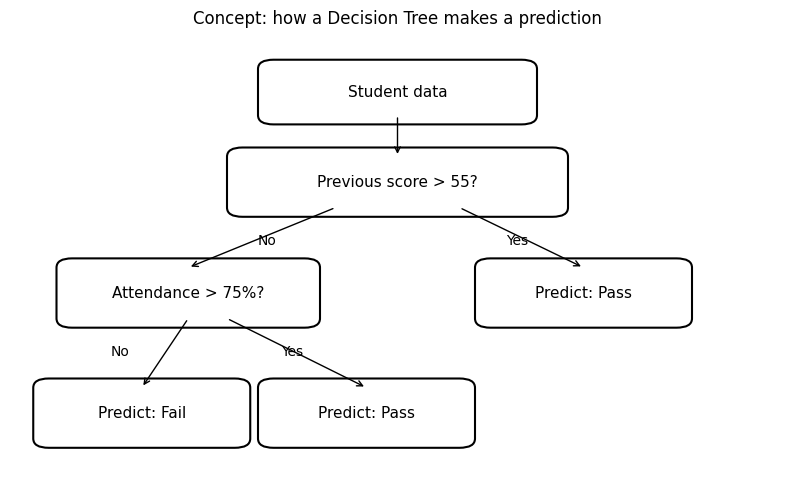

In [7]:
fig, ax = plt.subplots(figsize=(10, 6))
ax.set_xlim(0, 10)
ax.set_ylim(0, 10)
ax.axis("off")

def box(x, y, w, h, text):
    patch = FancyBboxPatch(
        (x, y), w, h,
        boxstyle="round,pad=0.2",
        fill=False,
        linewidth=1.5
    )
    ax.add_patch(patch)
    ax.text(x + w/2, y + h/2, text, ha="center", va="center", fontsize=11)

box(3.4, 8.2, 3.2, 1.0, "Student data")
box(3.0, 6.2, 4.0, 1.1, "Previous score > 55?")
box(0.8, 3.8, 3.0, 1.1, "Attendance > 75%?")
box(6.2, 3.8, 2.4, 1.1, "Predict: Pass")
box(0.5, 1.2, 2.4, 1.1, "Predict: Fail")
box(3.4, 1.2, 2.4, 1.1, "Predict: Pass")

ax.annotate("", xy=(5,7.3), xytext=(5,8.2), arrowprops=dict(arrowstyle="->"))
ax.annotate("", xy=(2.3,4.9), xytext=(4.2,6.2), arrowprops=dict(arrowstyle="->"))
ax.annotate("", xy=(7.4,4.9), xytext=(5.8,6.2), arrowprops=dict(arrowstyle="->"))
ax.annotate("", xy=(1.7,2.3), xytext=(2.3,3.8), arrowprops=dict(arrowstyle="->"))
ax.annotate("", xy=(4.6,2.3), xytext=(2.8,3.8), arrowprops=dict(arrowstyle="->"))

ax.text(3.2,5.4,"No")
ax.text(6.4,5.4,"Yes")
ax.text(1.3,3.0,"No")
ax.text(3.5,3.0,"Yes")

plt.title("Concept: how a Decision Tree makes a prediction")
plt.show()


### Train a real Decision Tree

We will start with `max_depth=3`, meaning the tree can grow to a maximum depth of three decision levels.


In [8]:
# Create the Decision Tree model
tree_model = DecisionTreeClassifier(
    max_depth=3,
    random_state=RANDOM_STATE
)

# FIT = learn the decision rules from the training data
tree_model.fit(X_train, y_train)

# .score() gives classification accuracy
# First: accuracy on data the model trained on
tree_train_accuracy = tree_model.score(X_train, y_train)

# Second: accuracy on unseen test data
tree_test_accuracy = tree_model.score(X_test, y_test)

print(f"Training accuracy: {tree_train_accuracy:.3f}")
print(f"Test accuracy:     {tree_test_accuracy:.3f}")


Training accuracy: 0.848
Test accuracy:     0.836


### Accuracy

Accuracy is:

**number of correct predictions / total number of predictions**

For example, an accuracy of `0.84` means about **84% of predictions were correct**.

We look at both:

- **training accuracy** - performance on examples the model learned from
- **test accuracy** - performance on unseen examples


## Visualise the real trained tree

Each box is called a **node**.

The important parts inside each box are:

- the first line: the question being asked
- `gini`: how mixed Pass/Fail examples are at that node
- `samples`: how many training examples reached that node
- `value = [Fail, Pass]`: how many of those examples are Fail vs Pass
- `class`: the majority class, so the prediction at that node

### Gini impurity - simple version

- `gini = 0` means the node contains only one class - completely pure
- a larger Gini means the node is more mixed
- for two balanced classes, Gini is around `0.5`

You do not need the Gini formula for this workshop.


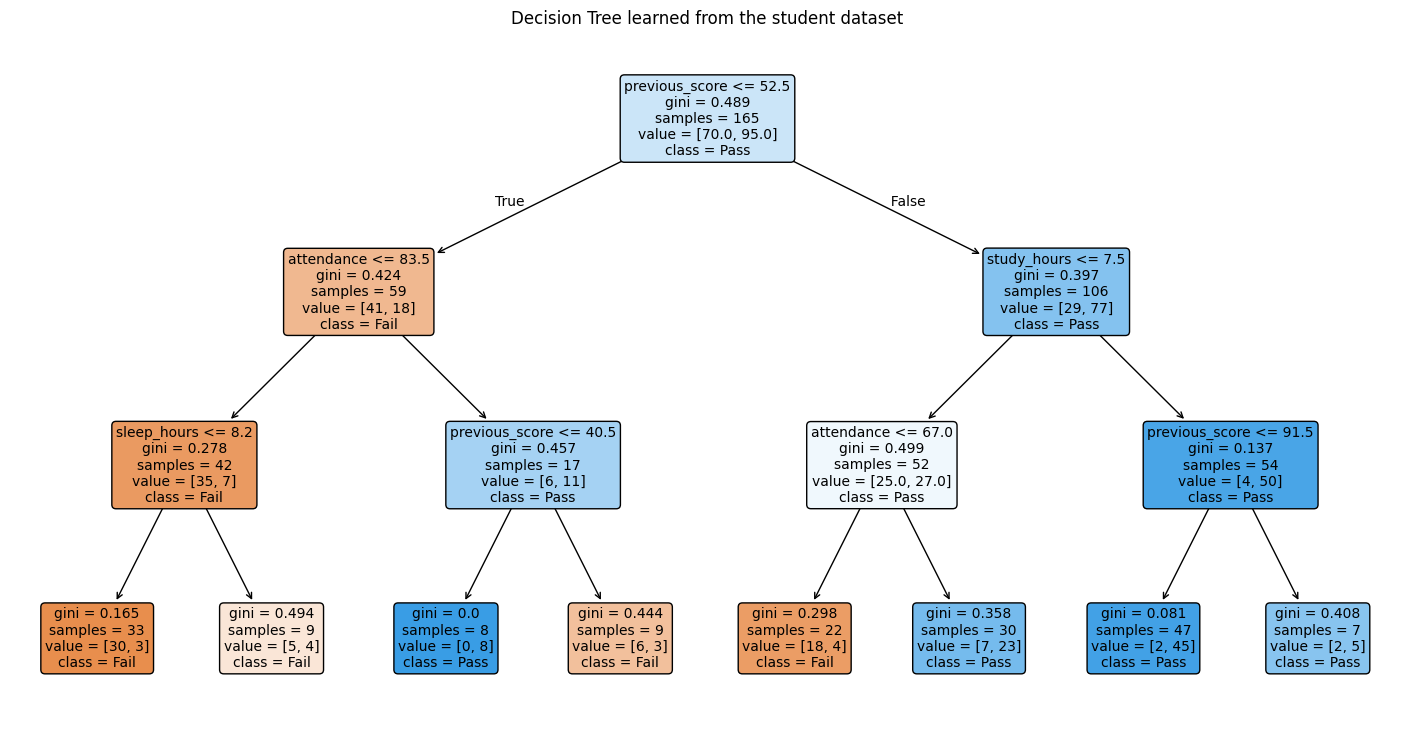

In [9]:
plt.figure(figsize=(18, 9))

plot_tree(
    tree_model,
    feature_names=features,
    class_names=["Fail", "Pass"],
    filled=True,
    rounded=True,
    fontsize=10
)

plt.title("Decision Tree learned from the student dataset")
plt.show()


### How to read one path

Start at the top.

For example, if the box says:

`previous_score <= 59.5`

- **True** -> go left
- **False** -> go right

Keep following the branches until you reach a leaf at the bottom.

**Mini-task:** Pick one complete path and explain it in normal English.


## How does the tree choose its questions?

The tree tries many possible questions such as:

- `attendance <= 72.5`
- `previous_score <= 60.5`
- `study_hours <= 7.5`

It chooses a split that makes the resulting groups **less mixed** in terms of Pass/Fail.

In this notebook, scikit-learn uses **Gini impurity** to measure how mixed a group is.

You only need this idea:

> a useful split separates the classes better than before


# 4. `max_depth` and overfitting

`max_depth` limits how deep the tree is allowed to grow.

### If the tree is too shallow
It may be too simple to capture useful patterns.

### If the tree is too deep
It can create lots of very specific rules that fit the training examples extremely well.

Some of those rules may just be fitting **noise or unusual cases** in the training data.

Those patterns may not appear in new data.

That is why making a tree deeper does **not** guarantee better test accuracy.

This is called **overfitting**.


In [10]:
# Try Decision Trees with different maximum depths
depths = range(1, 13)

train_scores = []
test_scores = []

for depth in depths:

    # Create a tree with this maximum depth
    model = DecisionTreeClassifier(
        max_depth=depth,
        random_state=RANDOM_STATE
    )

    # Train it
    model.fit(X_train, y_train)

    # Save its training and test accuracy
    train_scores.append(model.score(X_train, y_train))
    test_scores.append(model.score(X_test, y_test))

# Put the results into a table
results = pd.DataFrame({
    "max_depth": list(depths),
    "training_accuracy": train_scores,
    "test_accuracy": test_scores
})

results


,max_depth,training_accuracy,test_accuracy
0,1,0.715152,0.709091
1,2,0.745455,0.727273
2,3,0.848485,0.836364
3,4,0.896970,0.872727
4,5,0.933333,0.800000
5,6,0.969697,0.781818
6,7,0.993939,0.818182
7,8,1.000000,0.818182
8,9,1.000000,0.818182
9,10,1.000000,0.818182


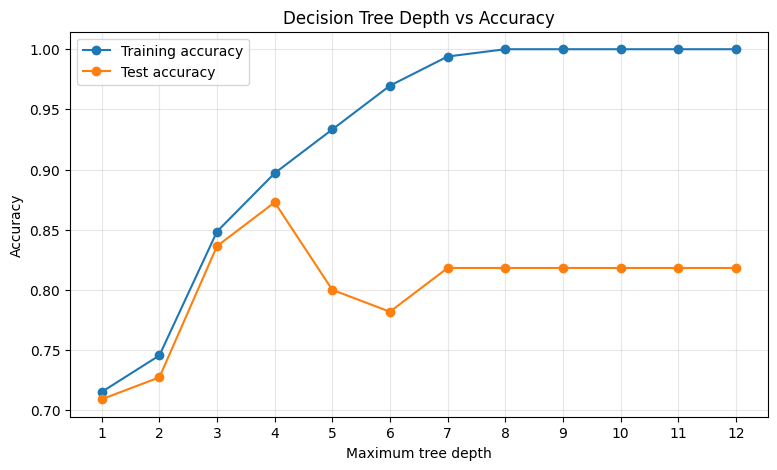

In [11]:
plt.figure(figsize=(9,5))

plt.plot(
    results["max_depth"],
    results["training_accuracy"],
    marker="o",
    label="Training accuracy"
)

plt.plot(
    results["max_depth"],
    results["test_accuracy"],
    marker="o",
    label="Test accuracy"
)

plt.xlabel("Maximum tree depth")
plt.ylabel("Accuracy")
plt.title("Decision Tree Depth vs Accuracy")
plt.xticks(list(depths))
plt.legend()
plt.grid(alpha=0.3)
plt.show()


### Discuss

1. What happens to training accuracy as depth increases?
2. Does test accuracy always improve?
3. Where do you see signs of overfitting?
4. Why is 100% training accuracy not automatically the goal?

### Answers

**1.** Training accuracy generally increases because a deeper tree can create more detailed rules.

**2.** No. Test accuracy may improve at first, then level off or decrease.

**3.** Overfitting appears when training accuracy keeps rising while test accuracy stops improving or falls.

**4.** A model can memorise the training data. We care about performance on new data, so test accuracy is more useful for checking generalisation.


# 5. Random Forests

A Random Forest is made from **many Decision Trees**.

Instead of trusting one tree:

1. build many slightly different trees
2. let each tree make a prediction
3. combine their predictions

For classification, you can think of this as a **vote**.


### Random Forest concept diagram


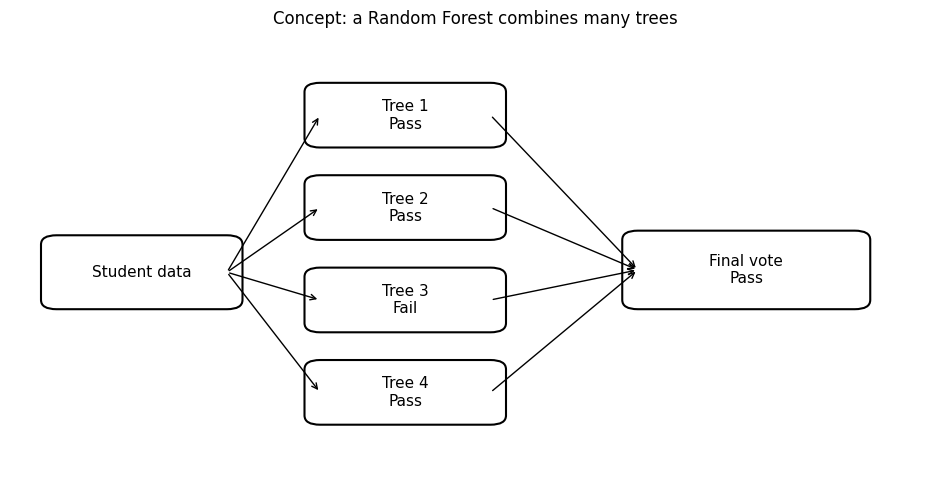

In [12]:
fig, ax = plt.subplots(figsize=(12,6))
ax.set_xlim(0,12)
ax.set_ylim(0,10)
ax.axis("off")

def box(x, y, w, h, text):
    patch = FancyBboxPatch(
        (x, y), w, h,
        boxstyle="round,pad=0.2",
        fill=False,
        linewidth=1.5
    )
    ax.add_patch(patch)
    ax.text(x+w/2, y+h/2, text, ha="center", va="center", fontsize=11)

box(0.6,4.2,2.2,1.2,"Student data")
box(4.0,7.7,2.2,1.0,"Tree 1\nPass")
box(4.0,5.7,2.2,1.0,"Tree 2\nPass")
box(4.0,3.7,2.2,1.0,"Tree 3\nFail")
box(4.0,1.7,2.2,1.0,"Tree 4\nPass")
box(8.1,4.2,2.8,1.3,"Final vote\nPass")

for y in [8.2,6.2,4.2,2.2]:
    ax.annotate("", xy=(4.0,y), xytext=(2.8,4.8), arrowprops=dict(arrowstyle="->"))

for y in [8.2,6.2,4.2,2.2]:
    ax.annotate("", xy=(8.1,4.85), xytext=(6.2,y), arrowprops=dict(arrowstyle="->"))

plt.title("Concept: a Random Forest combines many trees")
plt.show()


### Why are the trees different?

A Random Forest adds randomness so the trees do not all learn exactly the same rules.

At a high level:

- each tree sees a slightly different sample of the training data
- each split considers a random subset of the available features

This creates a collection of different trees.

Combining them often makes the final model more stable than relying on one tree.


### Train a Random Forest

Here we use:

- `n_estimators=100` -> build 100 trees
- `max_depth=5` -> each individual tree can grow to at most depth 5


In [13]:
# Create the Random Forest
forest_model = RandomForestClassifier(
    n_estimators=100,   # number of trees
    max_depth=5,        # maximum depth of each tree
    random_state=RANDOM_STATE
)

# Train all the trees in the forest
forest_model.fit(X_train, y_train)

# Accuracy on training data
forest_train_accuracy = forest_model.score(X_train, y_train)

# Accuracy on unseen test data
forest_test_accuracy = forest_model.score(X_test, y_test)

print(f"Training accuracy: {forest_train_accuracy:.3f}")
print(f"Test accuracy:     {forest_test_accuracy:.3f}")


Training accuracy: 0.921
Test accuracy:     0.873


### Why are training and test accuracy different?

The model was fitted using the training data, so it usually performs better there.

The test set contains unseen examples.

A gap between the two scores is normal.

A **very large** gap can be a warning sign that the model is overfitting.


## What does `n_estimators` mean?

`n_estimators` is simply the **number of trees in the Random Forest**.

For example:

- `n_estimators=1` -> one tree
- `n_estimators=10` -> ten trees
- `n_estimators=100` -> one hundred trees

More trees can make the combined prediction more stable, but more trees do **not** guarantee that test accuracy will keep increasing forever.

To make the comparison fair below, we keep `max_depth=5` the same and change only the number of trees.


In [14]:
tree_counts = [1, 5, 10, 25, 50, 100, 200]

train_scores = []
test_scores = []

for n in tree_counts:

    # Only n_estimators changes.
    # max_depth stays fixed at 5.
    model = RandomForestClassifier(
        n_estimators=n,
        max_depth=5,
        random_state=RANDOM_STATE
    )

    model.fit(X_train, y_train)

    train_scores.append(model.score(X_train, y_train))
    test_scores.append(model.score(X_test, y_test))

forest_results = pd.DataFrame({
    "number_of_trees": tree_counts,
    "training_accuracy": train_scores,
    "test_accuracy": test_scores
})

forest_results


,number_of_trees,training_accuracy,test_accuracy
0,1,0.739394,0.654545
1,5,0.896970,0.854545
2,10,0.909091,0.872727
3,25,0.939394,0.890909
4,50,0.927273,0.890909
5,100,0.921212,0.872727
6,200,0.933333,0.872727


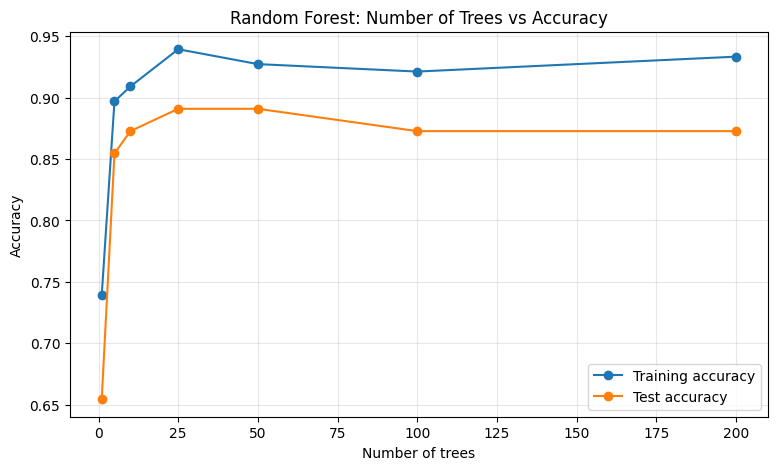

In [15]:
plt.figure(figsize=(9,5))

plt.plot(
    forest_results["number_of_trees"],
    forest_results["training_accuracy"],
    marker="o",
    label="Training accuracy"
)

plt.plot(
    forest_results["number_of_trees"],
    forest_results["test_accuracy"],
    marker="o",
    label="Test accuracy"
)

plt.xlabel("Number of trees")
plt.ylabel("Accuracy")
plt.title("Random Forest: Number of Trees vs Accuracy")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


### Discuss

1. Does adding more trees always increase test accuracy?
2. What happens once we have enough trees?
3. Why can many trees be more reliable than one?

### Answers

**1.** No. Test accuracy can move up and down slightly.

**2.** Performance often starts to stabilise. Adding more trees may give little or no extra accuracy.

**3.** Different trees make different mistakes. Combining their predictions reduces how much we depend on one particular tree.


# 6. Decision Tree vs Random Forest

Let's compare the two models we trained.


In [16]:
comparison = pd.DataFrame({
    "Model": ["Decision Tree", "Random Forest"],
    "Training Accuracy": [tree_train_accuracy, forest_train_accuracy],
    "Test Accuracy": [tree_test_accuracy, forest_test_accuracy]
})

comparison


,Model,Training Accuracy,Test Accuracy
0,Decision Tree,0.848485,0.836364
1,Random Forest,0.921212,0.872727


### Decision Tree

- one tree
- easy to visualise
- easy to explain
- can become unstable or overfit when very deep

### Random Forest

- many different trees
- combines their predictions
- usually more stable
- harder to explain as one simple set of rules
- takes more computation

### Which one is better?

There is no rule saying Random Forest is always better.

For this dataset, compare the **test accuracies**.

If the Random Forest performs better, the likely reason is that combining several trees has reduced the weaknesses of relying on one particular tree.

But if interpretability matters, a single Decision Tree may still be useful.


# 7. Workshop challenge

Change the values below and re-run the cell.

Try to find a model that performs well on the **test data**, not just the training data.


In [17]:
my_forest = RandomForestClassifier(
    n_estimators=50,   # try: 5, 10, 25, 50, 100, 200
    max_depth=3,       # try: 2, 3, 4, 5, 6, None
    random_state=RANDOM_STATE
)

my_forest.fit(X_train, y_train)

print("Training accuracy:", round(my_forest.score(X_train, y_train), 3))
print("Test accuracy:", round(my_forest.score(X_test, y_test), 3))


Training accuracy: 0.861
Test accuracy: 0.855


Try at least three combinations.

| Attempt | n_estimators | max_depth | Train accuracy | Test accuracy |
|---|---:|---:|---:|---:|
| 1 | | | | |
| 2 | | | | |
| 3 | | | | |

Which settings would you choose, and why?


# 8. Take-home challenges

### Challenge 1 - Find a good Decision Tree depth
Try different values of `max_depth`.

Can you find a depth with a good test score without making the tree unnecessarily deep?

### Challenge 2 - Make a tree overfit
Increase `max_depth` until training accuracy becomes extremely high.

What happens to test accuracy?

### Challenge 3 - Tune the Random Forest
Try combinations of:

```python
n_estimators
max_depth
```

### Challenge 4 - Remove a feature
Try using only:

```python
features = ["study_hours", "attendance", "previous_score"]
```

Re-run the notebook. Does the performance change?

### Challenge 5 - Explain it
In your own words:

> What is the difference between a Decision Tree and a Random Forest?


# 9. Final recap

**Decision Tree**  
A model that predicts by following learned decision rules.

**Random Forest**  
A collection of many Decision Trees whose predictions are combined.

**max_depth**  
Controls how deep each tree can grow.

**n_estimators**  
Controls how many trees are in a Random Forest.

**Training accuracy**  
Performance on examples the model trained on.

**Test accuracy**  
Performance on unseen examples.

**Overfitting**  
When a model fits the training data very closely but does not generalise as well to new data.

### Main takeaway

We do not want a model that simply memorises the training set.

We want a model that works well on **unseen data**.
